In [56]:
import ast
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from shapely.geometry import Polygon
from shapely.geometry import LineString
from scipy.spatial.distance import cdist

import visualizing_functions as visualizer

In [57]:
SHAPES_PATH = 'parsed_data/shapes.csv'
all_df = pd.read_csv(SHAPES_PATH)

In [58]:
counts = (
    all_df.groupby(["image_filename", "condition"])
    .size()
    .reset_index(name="count")
)

counts = counts.sort_values("count", ascending=False)
counts

,image_filename,condition,count
449,NAT17_HO_0007.jpg,Clustering,266
481,NAT21_HO_0016.jpg,Clustering,214
456,NAT18_HO_0009.jpg,Balance,188
40,ART06_AS_0009.jpeg,Balance,186
448,NAT17_HO_0007.jpg,Balance,185
...,...,...,...
258,ART33_TS_image_6.png,Configuring,25
618,NAT38_image_51.png,Configuring,24
186,ART24_TS_image_2.png,Configuring,24
578,NAT33_TS_image_60.png,Configuring,22


# To DO:

* Repetition
    - Shapes Only
    - Standard Clustering

* Emphasis
    - Shapes Only
    - Standard Clustering

* Clustering
    - Shapes Only
    - Standard Clustering

* Configuring
    - Shapes Only
    - Standard Clustering

* Linking
    - Lines Only
    - Standard Clustering

* Layering
    - 2 colors
        - Red Foreground
        - Blue Background

    - Cluster color seperately

* Balance
    - Colors
    - Pairs with the same color
    - Treat each pair as one region

* Segregating
    - Colors
    - Pairs with the same color
    - Treat each pair as one region

# DBSCAN Shapes

Used for:
* Repetition
* Emphasis
* Clustering
* Configuring

## Heatmap

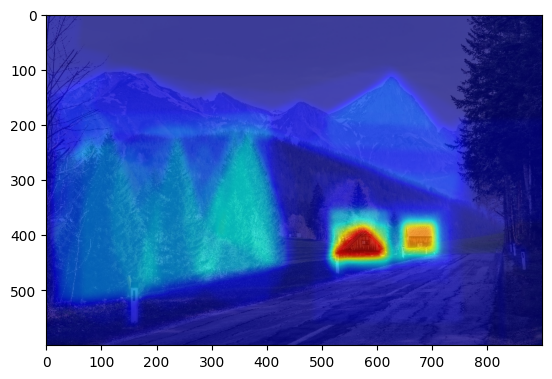

In [59]:
IMG_FILENAME = 'NAT07_AS_0006.jpg'
CONDITION = 'Emphasis'

filtered_df = all_df[
    (all_df["image_filename"] == IMG_FILENAME)
    & (all_df["condition"] == CONDITION)
]

# filtered_df = filtered_df[["point_coordinates", "type"]]

img = cv2.imread(visualizer.get_img_path(IMG_FILENAME))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

total_mask = visualizer.get_total_mask(img, filtered_df, line_thickness=5)
heatmap_img = visualizer.create_heatmap(img, total_mask)
plt.imshow(heatmap_img)
plt.show()

## Clustering

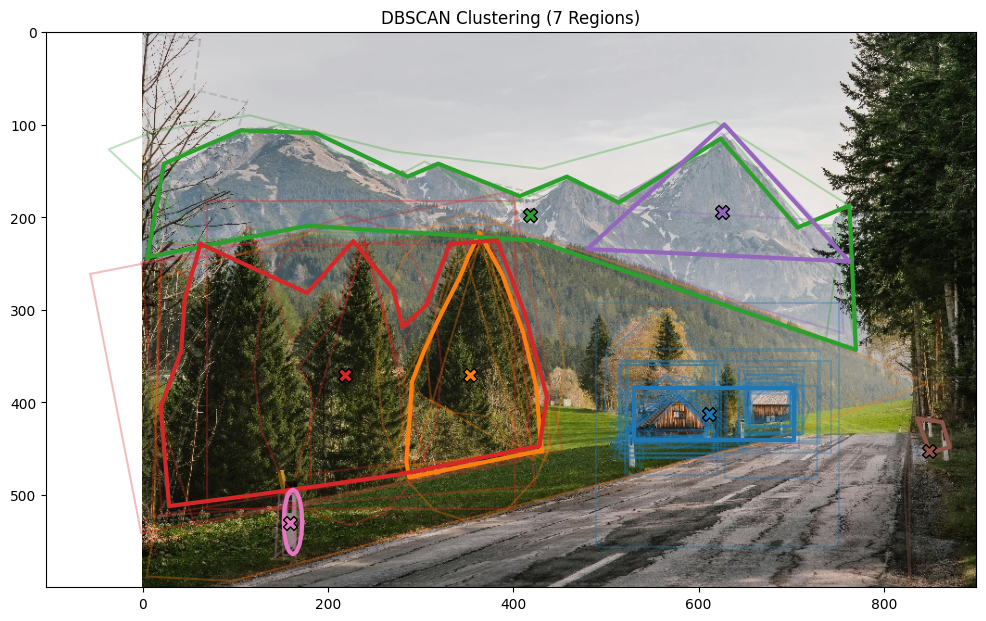

In [71]:
def cluster_shapes_DBSCAN(df, eps=75, min_samples=3):
    """
    Clusters shapes in the DataFrame using DBSCAN and returns the representative shapes 
    for each cluster, the cluster centers, and the DataFrame with cluster assignments.
    """
    
    # Create a copy to prevent SettingWithCopyWarning
    df = df.copy()
    df['coords'] = df['point_coordinates'].apply(ast.literal_eval)
    
    # Extract spatial centroids
    centroids = []
    polygons = []
    for coords in df['coords']:
        poly = Polygon(coords)
        polygons.append(poly)
        centroids.append([poly.centroid.x, poly.centroid.y])
    centroids = np.array(centroids)

    # Run DBSCAN
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    labels = dbscan.fit_predict(centroids)

    # Add the cluster assignments back to the DataFrame
    # (Note: -1 indicates a noise shape)
    df['cluster'] = labels

    unique_labels = set(labels)
    
    representative_indices = []
    cluster_centers = {}

    for k in unique_labels:
        if k == -1:
            continue  # Skip noise points
        
        class_member_mask = (labels == k)
        cluster_points = centroids[class_member_mask]
        
        # Calculate mathematical center of this cluster
        center = cluster_points.mean(axis=0)
        cluster_centers[k] = center
        
        # Find the shape whose centroid is closest to the cluster center
        distances = cdist(cluster_points, [center])
        closest_idx = np.where(class_member_mask)[0][np.argmin(distances)]
        representative_indices.append((k, closest_idx))

    df = df.drop(
        columns=["image_path", "canvas_height", "canvas_width", "label", 'transformed_points', 'points', 'vertices', 'coords']
    )

    return representative_indices, cluster_centers, df

def visualize_clusters(img, df, representative_indices, cluster_centers, save_path=None):
    """
    Visualizes the clusters on the image, highlighting the representative shapes.
    """

    # Create a copy to prevent SettingWithCopyWarning
    df = df.copy()
    df['coords'] = df['point_coordinates'].apply(ast.literal_eval)
    
    fig, ax = plt.subplots(figsize=(12, 8))
    cmap = plt.get_cmap('tab10')

    # Extract polygons
    polygons = []
    for coords in df['coords']:
        poly = Polygon(coords)
        polygons.append(poly)

    # Display your background image
    ax.imshow(img)

    # Plot all shapes (noise is dashed and gray, clustered shapes are colored)
    for i, poly in enumerate(polygons):
        x, y = poly.exterior.xy
        cluster_idx = df['cluster'].iloc[i]
        if cluster_idx == -1:
            ax.plot(x, y, color='gray', alpha=0.3, linestyle='--')  # Noise
        else:
            color = cmap(cluster_idx % 10)
            ax.plot(x, y, color=color, alpha=0.3)

    # Highlight the representative shape for each Region
    for k, rep_idx in representative_indices:
        poly = polygons[rep_idx]
        x, y = poly.exterior.xy
        color = cmap(k % 10)
        center = cluster_centers[k]

        # Draw thick outline and center 'X'
        ax.plot(x, y, color=color, linewidth=3, label=f'Region {k+1}')
        ax.scatter(center[0], center[1], color=color, marker='X', s=100, edgecolor='black', zorder=5)

    ax.set_aspect('equal')
    ax.set_title(f'DBSCAN Clustering ({len(set(df["cluster"])) - (1 if -1 in df["cluster"].values else 0)} Regions)')

    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300)

    else:
        plt.show()
    

representative_indices, cluster_centers, clustered_df = cluster_shapes_DBSCAN(filtered_df, eps=75, min_samples=3)

visualize_clusters(img, clustered_df, representative_indices, cluster_centers)

In [61]:
representative_indices

[(0, 76), (1, 9), (2, 7), (3, 15), (4, 18), (5, 72), (6, 79)]

# DBSCAN Lines

Used for:
* Linking

## Heatmap

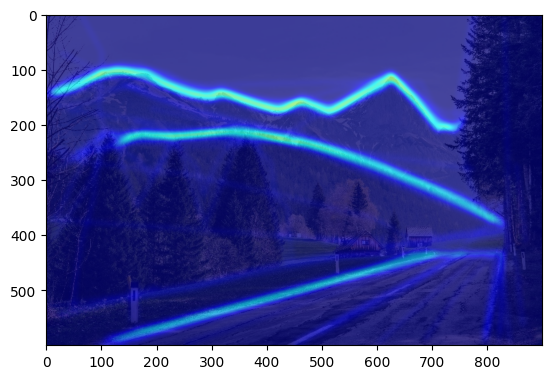

In [62]:
IMG_FILENAME = 'NAT07_AS_0006.jpg'
CONDITION = 'Linking'

filtered_df_lines = all_df[
    (all_df["image_filename"] == IMG_FILENAME)
    & (all_df["condition"] == CONDITION)
]

img = cv2.imread(visualizer.get_img_path(IMG_FILENAME))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

total_mask = visualizer.get_total_mask(img, filtered_df_lines, line_thickness=5)
heatmap_img = visualizer.create_heatmap(img, total_mask)
plt.imshow(heatmap_img)
plt.show()

## Clustering

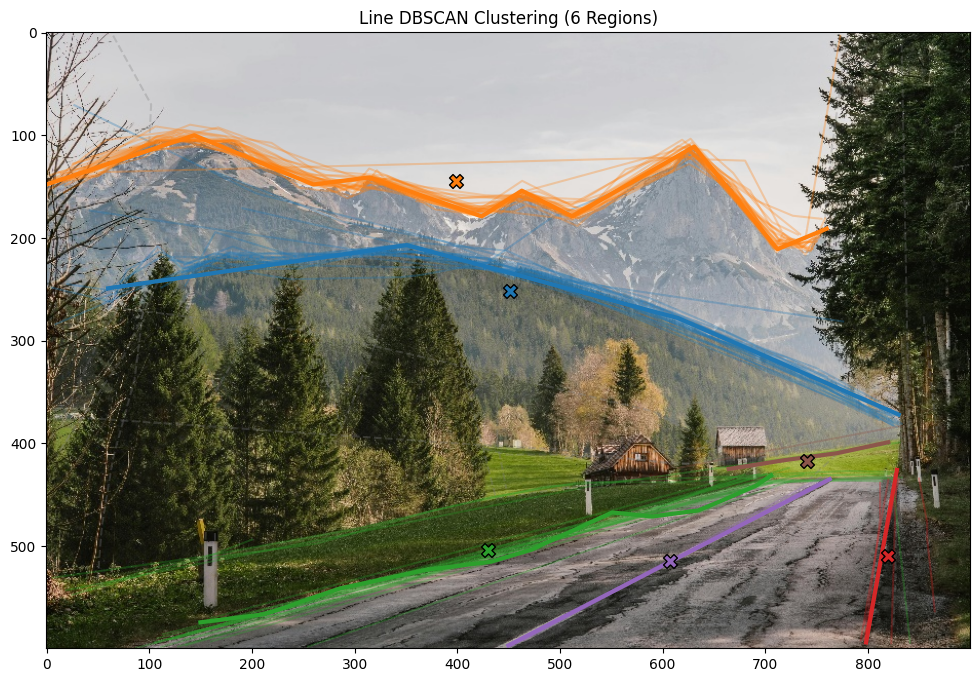

In [63]:

def cluster_lines_DBSCAN(df, eps=75, min_samples=3):
    """
    Clusters lines in the DataFrame using DBSCAN and returns the representative lines 
    for each cluster, the cluster centers, and the DataFrame with cluster assignments.
    """
    
    # Create a copy to prevent SettingWithCopyWarning
    df = df.copy()
    df['coords'] = df['point_coordinates'].apply(ast.literal_eval)
    
    # Extract spatial centroids
    centroids = []
    lines = []
    for coords in df['coords']:
        # Use LineString instead of Polygon for open paths
        line = LineString(coords)
        lines.append(line)
        centroids.append([line.centroid.x, line.centroid.y])
    centroids = np.array(centroids)

    # Run DBSCAN
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    labels = dbscan.fit_predict(centroids)

    # Add the cluster assignments back to the DataFrame
    df['cluster'] = labels

    unique_labels = set(labels)
    
    representative_indices = []
    cluster_centers = {}

    for k in unique_labels:
        if k == -1:
            continue  # Skip noise points
        
        class_member_mask = (labels == k)
        cluster_points = centroids[class_member_mask]
        
        # Calculate mathematical center of this cluster
        center = cluster_points.mean(axis=0)
        cluster_centers[k] = center
        
        # Find the line whose centroid is closest to the cluster center
        distances = cdist(cluster_points, [center])
        closest_idx = np.where(class_member_mask)[0][np.argmin(distances)]
        representative_indices.append((k, closest_idx))

    # Safely drop columns only if they exist in the dataframe
    cols_to_drop = ["image_path", "canvas_height", "canvas_width", "label", 'transformed_points', 'points', 'vertices', 'coords']
    df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

    return representative_indices, cluster_centers, df


def visualize_lines_clusters(img, df, representative_indices, cluster_centers, save_path=None):
    """
    Visualizes the clustered lines on the image, highlighting the representative lines.
    """

    # Create a copy to prevent SettingWithCopyWarning
    df = df.copy()
    df['coords'] = df['point_coordinates'].apply(ast.literal_eval)
    
    fig, ax = plt.subplots(figsize=(12, 8))
    cmap = plt.get_cmap('tab10')

    # Extract lines
    lines = []
    for coords in df['coords']:
        line = LineString(coords)
        lines.append(line)

    # Display your background image
    ax.imshow(img)

    # Plot all lines (noise is dashed and gray, clustered lines are colored)
    for i, line in enumerate(lines):
        # LineString uses .xy instead of .exterior.xy
        x, y = line.xy
        cluster_idx = df['cluster'].iloc[i]
        if cluster_idx == -1:
            ax.plot(x, y, color='gray', alpha=0.3, linestyle='--')  # Noise
        else:
            color = cmap(cluster_idx % 10)
            ax.plot(x, y, color=color, alpha=0.3)

    # Highlight the representative line for each Region
    for k, rep_idx in representative_indices:
        line = lines[rep_idx]
        x, y = line.xy
        color = cmap(k % 10)
        center = cluster_centers[k]

        # Draw thick line and center 'X'
        ax.plot(x, y, color=color, linewidth=3, label=f'Region {k+1}')
        ax.scatter(center[0], center[1], color=color, marker='X', s=100, edgecolor='black', zorder=5)

    ax.set_aspect('equal')
    n_clusters = len(set(df["cluster"])) - (1 if -1 in df["cluster"].values else 0)
    ax.set_title(f'Line DBSCAN Clustering ({n_clusters} Regions)')

    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
    else:
        plt.show()

representative_indices, cluster_centers, clustered_df = cluster_lines_DBSCAN(filtered_df_lines, eps=50, min_samples=3)
visualize_lines_clusters(img, clustered_df, representative_indices, cluster_centers)


# Layering

## Heatmap

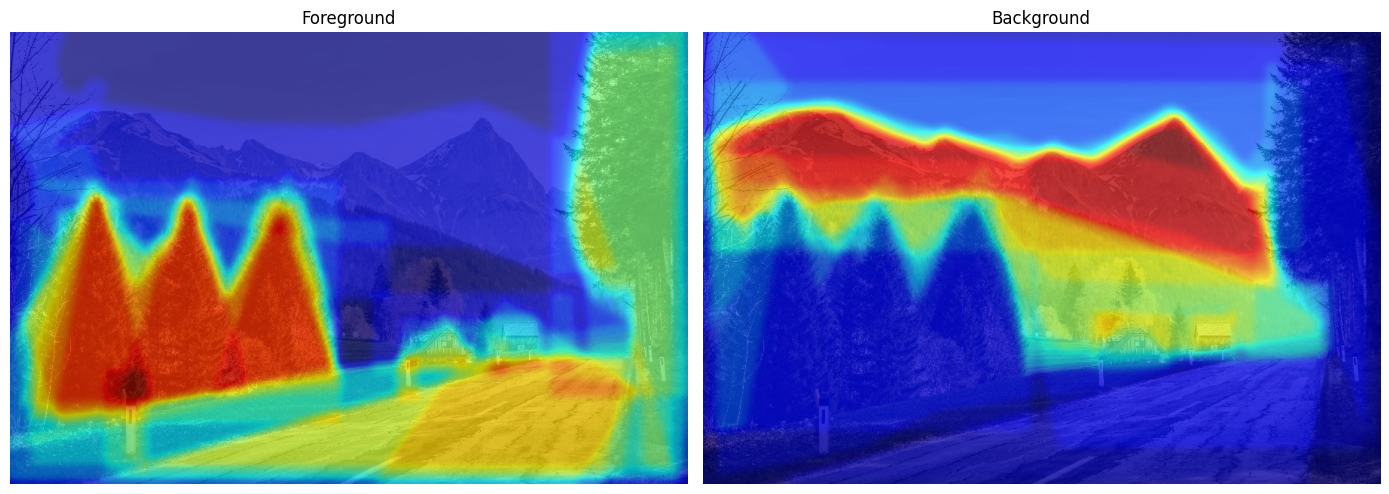

In [64]:
IMG_FILENAME = 'NAT07_AS_0006.jpg'
CONDITION = 'Layering'

filtered_df_layering = all_df[
    (all_df["image_filename"] == IMG_FILENAME)
    & (all_df["condition"] == CONDITION)
]

filtered_df_red = filtered_df_layering[filtered_df_layering['fill'] == 'rgb(255, 0, 0)']
filtered_df_blue = filtered_df_layering[filtered_df_layering['fill'] == 'rgb(41, 134, 204)']

img = cv2.imread(visualizer.get_img_path(IMG_FILENAME))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

total_mask_red = visualizer.get_total_mask(img, filtered_df_red, line_thickness=5)
total_mask_blue = visualizer.get_total_mask(img, filtered_df_blue, line_thickness=5)
heatmap_img_red = visualizer.create_heatmap(img, total_mask_red)
heatmap_img_blue = visualizer.create_heatmap(img, total_mask_blue)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(heatmap_img_red)
axes[0].set_title("Foreground")
axes[0].axis("off")

axes[1].imshow(heatmap_img_blue)
axes[1].set_title("Background")
axes[1].axis("off")

plt.tight_layout()
plt.show()

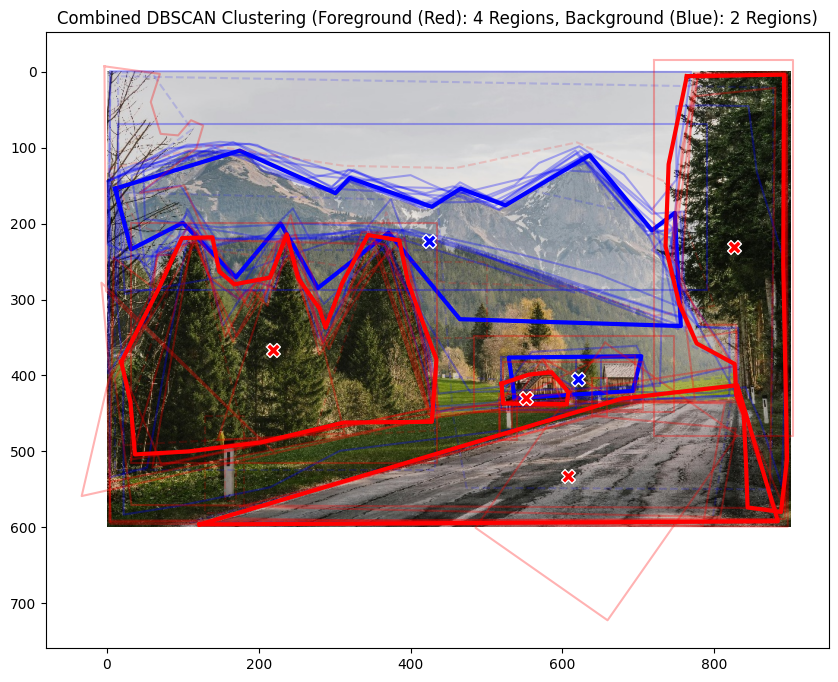

In [65]:
def visualize_combined_clusters(img, 
                                df_fg, rep_indices_fg, centers_fg, 
                                df_bg, rep_indices_bg, centers_bg, 
                                save_path=None):
    """
    Visualizes both foreground (red) and background (blue) clusters on the same image, 
    highlighting their respective representative shapes.
    """

    # Create copies and parse coordinates
    df_fg = df_fg.copy()
    df_fg['coords'] = df_fg['point_coordinates'].apply(ast.literal_eval)
    
    df_bg = df_bg.copy()
    df_bg['coords'] = df_bg['point_coordinates'].apply(ast.literal_eval)
    
    fig, ax = plt.subplots(figsize=(12, 8))

    # Display background image
    ax.imshow(img)

    # --- 1. PLOT BACKGROUND (BLUE) ---
    polygons_bg = [Polygon(c) for c in df_bg['coords']]
    for i, poly in enumerate(polygons_bg):
        x, y = poly.exterior.xy
        cluster_idx = df_bg['cluster'].iloc[i]
        if cluster_idx == -1:
            ax.plot(x, y, color='blue', alpha=0.15, linestyle='--')  # Noise
        else:
            ax.plot(x, y, color='blue', alpha=0.3)  # Clustered shape
            
    # Highlight Background Representatives
    for i, (k, rep_idx) in enumerate(rep_indices_bg):
        poly = polygons_bg[rep_idx]
        x, y = poly.exterior.xy
        center = centers_bg[k]
        
        # Only add the label once to keep the legend clean
        label = 'Background Rep' if i == 0 else ""
        ax.plot(x, y, color='blue', linewidth=3, label=label)
        ax.scatter(center[0], center[1], color='blue', marker='X', s=100, edgecolor='white', zorder=5)

    # --- 2. PLOT FOREGROUND (RED) ---
    polygons_fg = [Polygon(c) for c in df_fg['coords']]
    for i, poly in enumerate(polygons_fg):
        x, y = poly.exterior.xy
        cluster_idx = df_fg['cluster'].iloc[i]
        if cluster_idx == -1:
            ax.plot(x, y, color='red', alpha=0.15, linestyle='--')  # Noise
        else:
            ax.plot(x, y, color='red', alpha=0.3)  # Clustered shape
            
    # Highlight Foreground Representatives
    for i, (k, rep_idx) in enumerate(rep_indices_fg):
        poly = polygons_fg[rep_idx]
        x, y = poly.exterior.xy
        center = centers_fg[k]
        
        label = 'Foreground Rep' if i == 0 else ""
        ax.plot(x, y, color='red', linewidth=3, label=label)
        ax.scatter(center[0], center[1], color='red', marker='X', s=100, edgecolor='white', zorder=5)

    ax.set_aspect('equal')
    
    # Calculate cluster counts for the title
    n_bg = len(set(df_bg["cluster"])) - (1 if -1 in df_bg["cluster"].values else 0)
    n_fg = len(set(df_fg["cluster"])) - (1 if -1 in df_fg["cluster"].values else 0)
    ax.set_title(f'Combined DBSCAN Clustering (Foreground (Red): {n_fg} Regions, Background (Blue): {n_bg} Regions)')

    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
    else:
        plt.show()

representative_indices_foreground, cluster_centers_foreground, clustered_df_foreground = cluster_shapes_DBSCAN(filtered_df_red, eps=75, min_samples=3)
representative_indices_background, cluster_centers_background, clustered_df_background = cluster_shapes_DBSCAN(filtered_df_blue, eps=75, min_samples=3)

visualize_combined_clusters(
    img,
    clustered_df_foreground, representative_indices_foreground, cluster_centers_foreground,
    clustered_df_background, representative_indices_background, cluster_centers_background
)

# Pairs of Segments

In [66]:
IMG_FILENAME = 'NAT07_AS_0006.jpg'
CONDITION = 'Balance'

filtered_df_balance = all_df[
    (all_df["image_filename"] == IMG_FILENAME)
    & (all_df["condition"] == CONDITION)
]

# filtered_df_balance = filtered_df_balance[["point_coordinates", "type", "fill", "participant_id"]]

In [67]:
def extract_and_cluster_pairs(df, eps=100, min_samples=2):
    df = df.copy()
    df['coords'] = df['point_coordinates'].apply(ast.literal_eval)

    # 2. Compute centroid for every polygon in the dataset
    centroids = []
    for coords in df['coords']:
        centroids.append(Polygon(coords).centroid)
    df['centroid_x'] = [c.x for c in centroids]
    df['centroid_y'] = [c.y for c in centroids]

    # 3. Group by participant and color to find pairs
    pairs = []
    grouped = df.groupby(['participant_id', 'fill'])
    
    for (pid, color), group in grouped:
        # Filter strictly for pairs
        if len(group) == 2:
            pt1 = (group.iloc[0]['centroid_x'], group.iloc[0]['centroid_y'])
            pt2 = (group.iloc[1]['centroid_x'], group.iloc[1]['centroid_y'])
            
            pairs.append({
                'participant_id': pid,
                'fill_color_used': color,
                # Wrap the list in str() so literal_eval can safely parse it later
                'point_coordinates': str([pt1, pt2])  
            })
            
    # 4. Create a new DataFrame of just the pair connection lines
    pairs_df = pd.DataFrame(pairs)
    
    # 5. Pass it directly to our existing line clustering function
    # (Assuming cluster_lines_DBSCAN is already defined from our previous step)
    rep_indices, centers, clustered_pairs_df = cluster_lines_DBSCAN(
        pairs_df, eps=eps, min_samples=min_samples
    )
    
    return rep_indices, centers, clustered_pairs_df

rep_indices_pairs, centers_pairs, clustered_pairs_df = extract_and_cluster_pairs(filtered_df_balance, eps=100, min_samples=2)

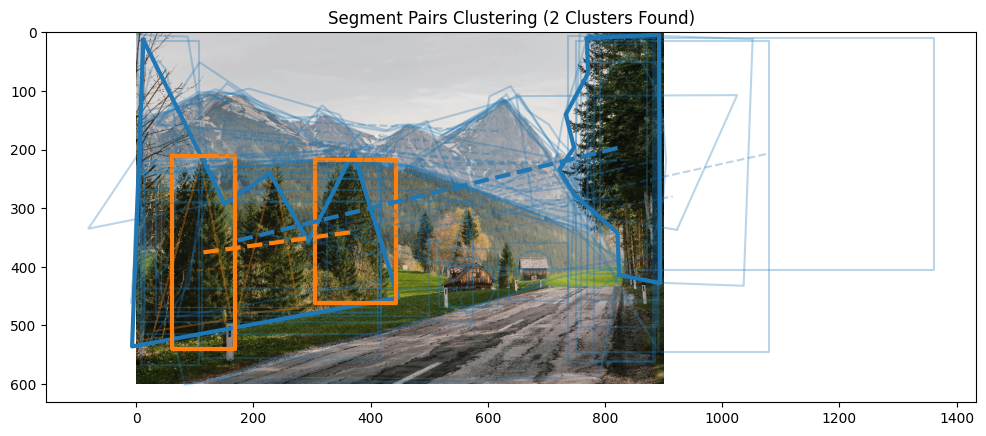

In [68]:
def visualize_all_segment_pairs(img, original_df, pairs_df, representative_indices, save_path=None):
    """
    Visualizes all original segments (polygons) and their connection lines using only edges.
    Non-representative pairs are semi-transparent; representatives are bold and opaque.
    """
    # Parse coordinates for the original dataset
    orig_df = original_df.copy()
    orig_df['coords'] = orig_df['point_coordinates'].apply(ast.literal_eval)
    
    fig, ax = plt.subplots(figsize=(12, 8))
    cmap = plt.get_cmap('tab10')

    # Display background image
    if img is not None:
        ax.imshow(img)

    # Helper function to handle drawing a pair of shape outlines and their connection
    def draw_pair(pid, fill_color, color, alpha, linewidth, label=""):
        shapes = orig_df[(orig_df['participant_id'] == pid) & (orig_df['fill'] == fill_color)]
        centroids = []
        
        # Draw the shape edges only
        for idx, shape_row in enumerate(shapes.itertuples()):
            poly = Polygon(shape_row.coords)
            x, y = poly.exterior.xy
            centroids.append((poly.centroid.x, poly.centroid.y))
            
            # Only label the first polygon to avoid legend duplicates
            lbl = label if idx == 0 else ""
            ax.plot(x, y, color=color, linewidth=linewidth, label=lbl, alpha=alpha)
                
        # Draw dashed connecting line between the shapes
        if len(centroids) == 2:
            c1, c2 = centroids[0], centroids[1]
            ax.plot([c1[0], c2[0]], [c1[1], c2[1]], color=color, linestyle='--', 
                    linewidth=linewidth, alpha=alpha, zorder=4)

    # 1. Draw all non-representative (and noise) pairs first (as background)
    rep_idx_set = {rep_idx for _, rep_idx in representative_indices}
    
    for idx, row in pairs_df.iterrows():
        if idx in rep_idx_set:
            continue  # Skip representatives, we'll draw them on top
            
        cluster_id = row['cluster']
        pid = row['participant_id']
        fill_color = row['fill_color_used']
        
        if cluster_id == -1:
            # Noise pairs in semi-transparent gray edges
            draw_pair(pid, fill_color, color='gray', alpha=0.3, linewidth=1)
        else:
            # Clustered pairs in semi-transparent cluster color edges
            c_color = cmap(cluster_id % 10)
            draw_pair(pid, fill_color, color=c_color, alpha=0.3, linewidth=1.5)

    # 2. Draw representative pairs on top with high opacity edges
    valid_clusters = 0
    for k, rep_idx in representative_indices:
        if k == -1:
            continue
            
        valid_clusters += 1
        cluster_color = cmap(k % 10)
        rep_pair_row = pairs_df.iloc[rep_idx]
        pid = rep_pair_row['participant_id']
        fill_color = rep_pair_row['fill_color_used']
        
        draw_pair(pid, fill_color, color=cluster_color, alpha=1.0, linewidth=3, 
                  label=f'Cluster {k+1} Rep')

    ax.set_aspect('equal')
    ax.set_title(f'Segment Pairs Clustering ({valid_clusters} Clusters Found)')

    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
    else:
        plt.show()

    plt.close()

visualize_all_segment_pairs(img, filtered_df_balance, clustered_pairs_df, rep_indices_pairs)